# Customer Churn Prediction Using Machine Learning
**University of Lahore – Faculty of IT | Course: Artificial Intelligence**

**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 columns)  
**Goal:** Predict whether a customer will leave the telecom company (`Churn = Yes`) or stay (`Churn = No`).

**Pipeline followed in this notebook**
1. Data Loading and Understanding
2. Data Preprocessing
3. Exploratory Data Analysis (EDA)
4. Feature Engineering and Encoding
5. Training and Testing
6. Model Evaluation
7. Application / Prediction
8. Conclusion

> **How to run:** Put this notebook in the same folder as the dataset file (`WA_Fn-UseC_-Telco-Customer-Churn.xlsx` or `.csv`) and choose *Kernel → Restart & Run All*.  
> Every cell uses `random_state=42`, so the results are reproducible.

---
# 1. DATA LOADING AND UNDERSTANDING

### Step 1.1 – Import libraries
**What:** We import all the Python libraries used in this project.  
**Why:** `pandas`/`numpy` handle data, `matplotlib`/`seaborn` draw charts, and `scikit-learn` provides the machine-learning tools.  
**Output meaning:** If there is no error, the libraries are installed correctly. We also set a global `RANDOM_STATE = 42` so that every random operation gives the same result each time.

In [1]:
import warnings
warnings.filterwarnings("ignore")      # keep the notebook output clean

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix,
                             roc_curve, roc_auc_score)

RANDOM_STATE = 42                      # used everywhere for reproducibility
sns.set_theme(style="whitegrid")       # nice default look for all charts
pd.set_option("display.max_columns", 50)
print("Libraries imported successfully.")

Libraries imported successfully.


### Step 1.2 – Load the dataset
**What:** We read the dataset into a pandas DataFrame called `df`. The assignment file is an Excel file, so we use `pd.read_excel`. As a safety fallback, if only the `.csv` version of the same dataset is present, the code reads that with `pd.read_csv` instead (the data inside is identical).  
**Why:** All later steps need the data inside Python.  
**Output meaning:** The message tells us which file was loaded and how many rows and columns it has.

In [2]:
XLSX_FILE = "WA_Fn-UseC_-Telco-Customer-Churn.xlsx"
CSV_FILE  = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

if os.path.exists(XLSX_FILE):
    df = pd.read_excel(XLSX_FILE)          # main method required by the assignment
    print("Loaded Excel file:", XLSX_FILE)
elif os.path.exists(CSV_FILE):
    df = pd.read_csv(CSV_FILE)             # fallback if only the CSV copy is available
    print("Loaded CSV file:", CSV_FILE)
else:
    raise FileNotFoundError("Dataset not found. Put it in the same folder as this notebook.")

print("Rows, Columns:", df.shape)

# Keep an untouched copy of the raw data. We use it later to test that our
# prediction function applies exactly the same preprocessing as training.
df_raw = df.copy()

Loaded CSV file: WA_Fn-UseC_-Telco-Customer-Churn.csv
Rows, Columns: (7043, 21)


### Step 1.3 – First look at the data
**What:** `df.head()` shows the first 5 customers; `df.shape` gives (rows, columns); `df.columns` lists the column names.  
**Why:** Before cleaning anything we must see what the data looks like.  
**Output meaning:** Each row is one customer and each column is one piece of information about that customer. The shape tells us we have 7,043 customers and 21 columns.

In [3]:
display(df.head())
print("Shape (rows, columns):", df.shape)
print("\nColumn names:")
print(list(df.columns))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Shape (rows, columns): (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


### Step 1.4 – Data types and basic information
**What:** `df.info()` shows each column's data type and the number of non-null values.  
**Why:** Wrong data types cause errors later (for example a number stored as text). Checking now helps us find such problems early.  
**Output meaning:** Most columns are `object` (text). **Look closely at `TotalCharges`** – it should be a number but it is stored as text. We will fix this in Section 2.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Step 1.5 – Basic statistics
**What:** `describe()` summarises the data. First for the numeric columns (count, mean, min, max, quartiles) and then for the categorical (text) columns (number of unique values, most frequent value and its count).  
**Why:** This gives a quick feel for the scale and spread of the data and reveals unusual values.  
**Output meaning:** For example, `tenure` ranges from 0 to 72 months and `MonthlyCharges` ranges from about 18 to 119. In the categorical table, `top` is the most common value and `freq` is how many times it occurs.

In [5]:
print("=== Numeric columns ===")
display(df.describe())

print("\n=== Categorical (text) columns ===")
display(df.describe(exclude="number").T)

=== Numeric columns ===


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



=== Categorical (text) columns ===


,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


### Step 1.6 – Identify the target variable
**What:** The target variable (the thing we want to predict) is `Churn`. We count its values.  
**Why:** In supervised learning we must know exactly which column is the label (`y`) and which columns are the inputs (`X`).  
**Output meaning:** `Yes` = the customer left the company, `No` = the customer stayed. Notice that there are many more `No` than `Yes` – we will discuss this *class imbalance* later.

In [6]:
print("Target variable: Churn")
print(df["Churn"].value_counts())

Target variable: Churn
Churn
No     5174
Yes    1869
Name: count, dtype: int64


### Step 1.7 – What do the important columns mean?

| Column | Plain-language meaning |
|---|---|
| **customerID** | A unique ID for each customer (like a roll number). It is only a label, not useful for prediction. |
| **gender** | Male or Female. |
| **SeniorCitizen** | 1 if the customer is a senior citizen (65+), otherwise 0. |
| **Partner** | Does the customer have a partner (spouse)? Yes/No. |
| **Dependents** | Does the customer have dependents such as children or parents to support? Yes/No. |
| **tenure** | How many months the customer has been with the company. |
| **PhoneService** | Does the customer have a phone line? Yes/No. |
| **MultipleLines** | Does the customer have more than one phone line? (Yes / No / No phone service) |
| **InternetService** | Type of internet: DSL, Fiber optic, or No internet. |
| **OnlineSecurity** | Has the extra online security service? (Yes / No / No internet service) |
| **TechSupport** | Has the extra technical support service? (Yes / No / No internet service) |
| **Contract** | Contract length: Month-to-month, One year, or Two year. |
| **PaperlessBilling** | Does the customer receive bills by e-mail instead of paper? Yes/No. |
| **PaymentMethod** | How the customer pays: Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic). |
| **MonthlyCharges** | The amount charged to the customer every month. |
| **TotalCharges** | The total amount charged to the customer since joining. |
| **Churn** | **Target.** Did the customer leave in the last month? Yes/No. |

The remaining columns (`OnlineBackup`, `DeviceProtection`, `StreamingTV`, `StreamingMovies`) are other optional add-on services (Yes / No / No internet service).

---
# 2. DATA PREPROCESSING

Real-world data is usually messy. Machine-learning models need clean numeric data, so here we check quality problems and fix them. **Every decision is explained.**

### Step 2.1 – Check missing values and duplicates
**What:** We count missing (null) values per column and the number of fully duplicated rows.  
**Why:** Missing values and duplicates can reduce model quality or cause errors.  
**Output meaning:** If every count is 0, pandas found no *obvious* missing values and no duplicate rows. (But a hidden problem may still exist – see the next step.)

In [7]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total missing values: 0


Duplicate rows: 0


### Step 2.2 – Find the hidden problem in `TotalCharges`
**What:** `TotalCharges` should be numeric, but `info()` showed it as text. We convert it with `pd.to_numeric(errors="coerce")`. The option `errors="coerce"` turns anything that is not a number (like a blank space) into `NaN` instead of crashing. Then we look at the rows that became `NaN`.  
**Why:** The blank values are invisible to `isnull()` because they are stored as empty strings (`" "`), not as real nulls. A model cannot work with text in a numeric column.  
**Output meaning:** Only **11 rows** become `NaN`, and **all of them have `tenure = 0`**. These are brand-new customers who have not yet received their first bill, so their total charge is truly zero.

In [8]:
# Convert text -> number. Blank strings become NaN.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("TotalCharges data type now:", df["TotalCharges"].dtype)
print("Missing values in TotalCharges:", df["TotalCharges"].isnull().sum())
print("\nThese are the rows with missing TotalCharges:")
display(df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

TotalCharges data type now:

 float64
Missing values in TotalCharges: 11

These are the rows with missing TotalCharges:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


### Step 2.3 – Handle the missing `TotalCharges` (fill with 0)
**What:** We fill the 11 `NaN` values with `0`.  
**Why (justification):** All 11 customers have `tenure = 0`, meaning they just joined and have not been billed yet. So the real total charge is exactly **0**, not an unknown value. Filling with 0 is therefore the *logically correct* choice. Dropping them would also work (only 11 of 7,043 rows), but we prefer to keep all customers. We do **not** use the mean, because that would wrongly say a brand-new customer paid about 2,300.  
**Output meaning:** After filling, there should be 0 missing values left.

In [9]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Missing values in TotalCharges after fixing:", df["TotalCharges"].isnull().sum())
print("Total missing values in whole dataset:", df.isnull().sum().sum())

Missing values in TotalCharges after fixing:

 0
Total missing values in whole dataset: 0


### Step 2.4 – Drop `customerID`
**What:** We remove the `customerID` column.  
**Why:** It is a unique code for every customer. It carries no real information about behaviour, so it has no predictive value. Keeping it could even confuse the model into memorising individual customers (overfitting).  
**Output meaning:** The number of columns reduces from 21 to 20.

In [10]:
df = df.drop(columns=["customerID"])
print("Shape after dropping customerID:", df.shape)

# After removing the ID, some rows look identical. These are DIFFERENT customers
# who just happen to have the same answers, so we keep them (they are not real duplicates).
print("Rows that look identical after dropping the ID:", df.duplicated().sum(), "(kept on purpose)")

Shape after dropping customerID: (7043, 20)


Rows that look identical after dropping the ID: 22 (kept on purpose)


### Step 2.5 – Make `SeniorCitizen` consistent
**What:** `SeniorCitizen` is stored as 0/1 while every other Yes/No column uses the words "Yes"/"No". We convert 0 → "No" and 1 → "Yes".  
**Why:** Having all yes/no columns in the same format makes the data easier to read, to plot (clear labels in charts) and to encode in one consistent way later.  
**Output meaning:** The counts show about 16% of customers are senior citizens.

In [11]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
print(df["SeniorCitizen"].value_counts())

SeniorCitizen
No     5901
Yes    1142
Name: count, dtype: int64


### Step 2.6 – Simplify "No internet service" and "No phone service" to "No"
**What:** Columns like `OnlineSecurity`, `TechSupport`, `StreamingTV` have three values: *Yes*, *No* and *No internet service*. `MultipleLines` has *No phone service*. We replace both special values with `"No"`.  
**Why:** "No internet service" simply means the customer does not have the add-on service – the same as "No". The information that the customer has no internet is **already stored** in the `InternetService` column (and `PhoneService` column for phone). Keeping duplicate categories would only create extra, redundant columns after encoding. After this step these columns become clean **binary** (Yes/No) columns.  
**Note:** We do **not** change `InternetService` itself – its value "No" there means "no internet connection", which is a real category.  
**Output meaning:** Each of these columns now shows only `Yes` and `No`.

In [12]:
service_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]

for col in service_cols:
    df[col] = df[col].replace("No internet service", "No")

df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

# Check the result
for col in service_cols + ["MultipleLines"]:
    print(f"{col:18s} ->", sorted(df[col].unique()))

OnlineSecurity     -> ['No', 'Yes']
OnlineBackup       -> ['No', 'Yes']
DeviceProtection   -> ['No', 'Yes']
TechSupport        -> ['No', 'Yes']
StreamingTV        -> ['No', 'Yes']
StreamingMovies    -> ['No', 'Yes']
MultipleLines      -> ['No', 'Yes']


### Step 2.7 – Final data-quality check
**What:** We print the data types again and show the first rows of the cleaned data.  
**Why:** To confirm all cleaning steps worked: `TotalCharges` is now numeric, there are no missing values, and the ID is gone.  
**Output meaning:** Numeric columns: `tenure`, `MonthlyCharges`, `TotalCharges`. All others are text categories, which we will encode in Section 4.

In [13]:
print("Missing values:", df.isnull().sum().sum())
print("Shape:", df.shape)
print()
print(df.dtypes)
display(df.head())

Missing values: 0
Shape: (7043, 20)

gender                  str
SeniorCitizen           str
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


---
# 3. EXPLORATORY DATA ANALYSIS (EDA)

EDA means "looking at the data with tables and charts to discover patterns" before building models. It tells us which features matter and guides our feature engineering.

### Step 3.1 – Churn distribution
**What:** A count plot and the percentage of customers who churned vs stayed.  
**Why:** We must know if the two classes are balanced. Many ML models become biased toward the bigger class if the data is imbalanced.  
**Output meaning:** About **73% stayed** and **27% churned**. The data is **imbalanced** (roughly 2.7 : 1). A lazy model that always predicts "No" would already get ~73% accuracy while catching **zero** churners – so accuracy alone is a misleading metric here. We will handle this with `class_weight="balanced"` and focus on Recall/F1.

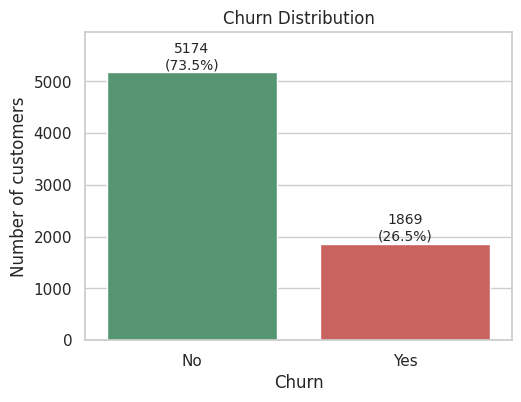

Churn
No     73.46 %
Yes    26.54 %
Name: proportion, dtype: str


In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 4))
sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette=["#4C9F70", "#D9534F"],
    legend=False,
    ax=ax
)
ax.set_title("Churn Distribution")
ax.set_ylabel("Number of customers")

# write the count and percentage on top of each bar
total = len(df)
for p in ax.patches:
    count = int(p.get_height())
    ax.annotate(f"{count}\n({count/total*100:.1f}%)", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, df["Churn"].value_counts().max() * 1.15)
plt.show()

print((df["Churn"].value_counts(normalize=True) * 100).round(2).astype(str) + " %")

### Step 3.2 – Churn rate by categorical features
**What:** For six categorical features (Contract, InternetService, PaymentMethod, TechSupport, SeniorCitizen, PaperlessBilling) we plot the **churn rate** – the percentage of customers in each category who churned.  
**Why:** Showing the *rate* (not the raw count) lets us compare groups fairly even when the groups have different sizes.  
**Output meaning:** The taller the bar, the more likely that group is to leave. The dashed line is the overall churn rate (~26.5%); bars above it are higher-risk groups.

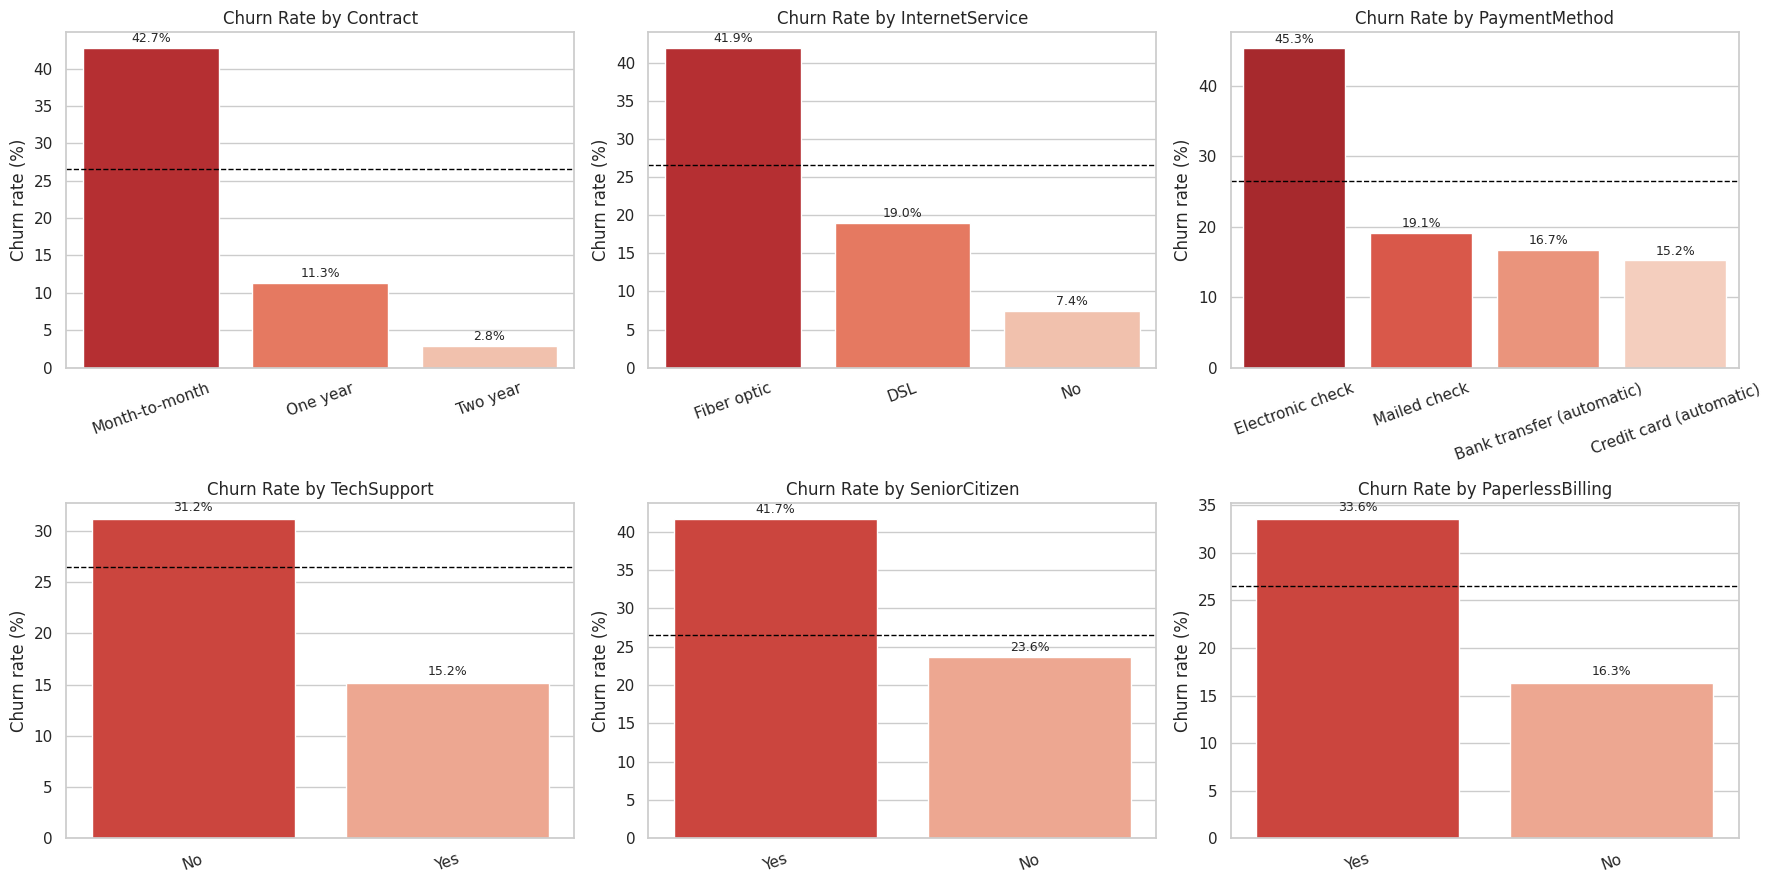

In [15]:
df["Churn_num"] = (df["Churn"] == "Yes").astype(int)   # temporary helper column for plotting rates
overall_rate = df["Churn_num"].mean() * 100

cat_features = ["Contract", "InternetService", "PaymentMethod",
                "TechSupport", "SeniorCitizen", "PaperlessBilling"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), cat_features):
    rate = df.groupby(col)["Churn_num"].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, palette="Reds_r", ax=ax)
    ax.axhline(overall_rate, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"Churn Rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.8, f"{v:.1f}%", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

### Step 3.3 – Tenure and MonthlyCharges vs Churn (histogram/KDE and boxplot)
**What:** For the two important numeric features we draw (top) histograms with a KDE smooth curve, split by churn, and (bottom) boxplots.  
**Why:** Histograms show *where* customers of each group are concentrated; boxplots compare the median and spread.  
**Output meaning:**  
- **Tenure:** churned customers are concentrated at **low tenure** (mostly the first few months); loyal customers have a much higher median tenure.  
- **MonthlyCharges:** churned customers pay **more per month** on average (higher median), mostly in the 70–100 range.

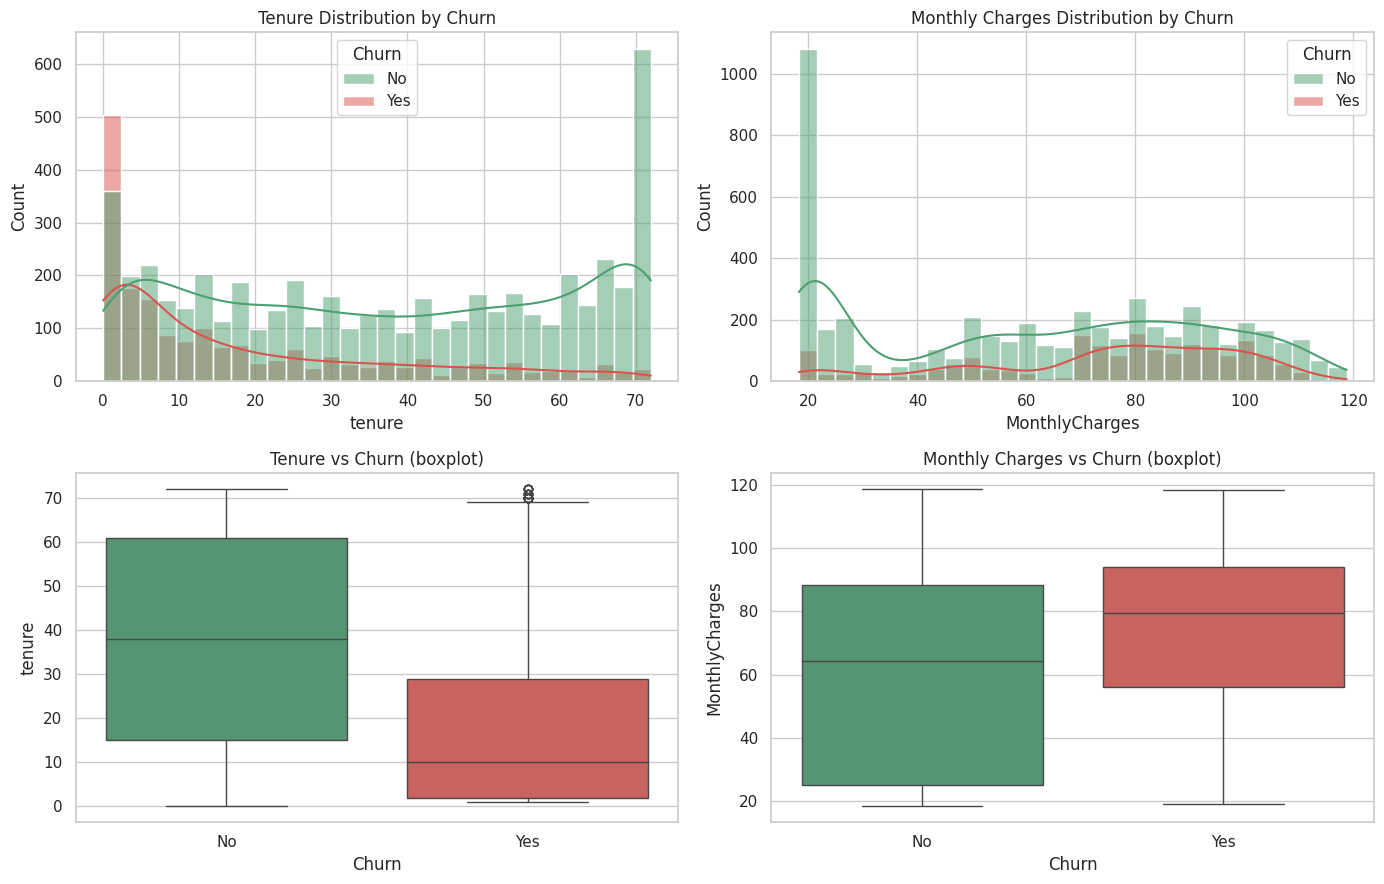

Average / median values by churn group:


tenure        MonthlyCharges        TotalCharges        
        mean median           mean median         mean  median
Churn                                                         
No      37.6   38.0           61.3   64.4       2549.9  1679.5
Yes     18.0   10.0           74.4   79.6       1531.8   703.6

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
palette = {"No": "#4C9F70", "Yes": "#D9534F"}

sns.histplot(data=df, x="tenure", hue="Churn", kde=True, bins=30, palette=palette, ax=axes[0, 0])
axes[0, 0].set_title("Tenure Distribution by Churn")

sns.histplot(data=df, x="MonthlyCharges", hue="Churn", kde=True, bins=30, palette=palette, ax=axes[0, 1])
axes[0, 1].set_title("Monthly Charges Distribution by Churn")

sns.boxplot(data=df, x="Churn", y="tenure", palette=palette, ax=axes[1, 0])
axes[1, 0].set_title("Tenure vs Churn (boxplot)")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=palette, ax=axes[1, 1])
axes[1, 1].set_title("Monthly Charges vs Churn (boxplot)")

plt.tight_layout()
plt.show()

print("Average / median values by churn group:")
display(df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].agg(["mean", "median"]).round(1))

### Step 3.4 – Correlation heatmap (numeric features)
**What:** A heatmap of the correlation between numeric columns (and churn converted to 0/1). Correlation ranges from -1 to +1.  
**Why:** It shows which numeric features move together with churn and warns us about features that are highly related to each other.  
**Output meaning:**  
- `tenure` has a **negative** correlation with churn (longer stay → less churn).  
- `MonthlyCharges` has a small **positive** correlation with churn.  
- `TotalCharges` is strongly correlated with `tenure` (because total = monthly × months), so these two carry overlapping information.

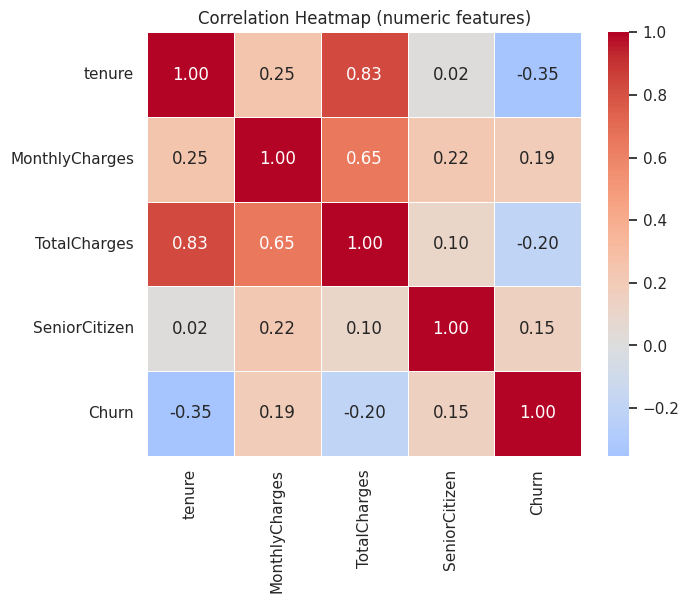

In [17]:
corr_df = df[["tenure", "MonthlyCharges", "TotalCharges"]].copy()
corr_df["SeniorCitizen"] = (df["SeniorCitizen"] == "Yes").astype(int)
corr_df["Churn"] = df["Churn_num"]

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap (numeric features)")
plt.show()

### Step 3.5 – Numbers behind the observations
**What:** A small table of churn rates for the key groups, so our observations are backed by exact numbers.  
**Why:** Good analysis uses numbers, not only visual impressions.  
**Output meaning:** Read each line as "X% of customers in this group churned".

In [18]:
for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport", "SeniorCitizen"]:
    print(f"--- Churn rate by {col} ---")
    print(df.groupby(col)["Churn_num"].mean().mul(100).round(1).sort_values(ascending=False).astype(str) + " %")
    print()

--- Churn rate by Contract ---
Contract
Month-to-month    42.7 %
One year          11.3 %
Two year           2.8 %
Name: Churn_num, dtype: str

--- Churn rate by InternetService ---
InternetService
Fiber optic    41.9 %
DSL            19.0 %
No              7.4 %
Name: Churn_num, dtype: str

--- Churn rate by PaymentMethod ---
PaymentMethod
Electronic check             45.3 %
Mailed check                 19.1 %
Bank transfer (automatic)    16.7 %
Credit card (automatic)      15.2 %
Name: Churn_num, dtype: str

--- Churn rate by TechSupport ---
TechSupport
No     31.2 %
Yes    15.2 %
Name: Churn_num, dtype: str

--- Churn rate by SeniorCitizen ---
SeniorCitizen
Yes    41.7 %
No     23.6 %
Name: Churn_num, dtype: str



### Step 3.6 – Key observations from EDA
1. **Class imbalance:** only about 26.5% of customers churned, so accuracy alone is not enough to judge a model.
2. **Contract type is the strongest pattern:** month-to-month customers churn at about **43%**, compared to about 11% (one-year) and only about 3% (two-year). Long contracts keep customers.
3. **Tenure matters a lot:** churners are mostly *new* customers. The median tenure of churned customers is about 10 months versus about 38 months for loyal ones.
4. **Fiber optic customers churn the most (~42%)**, compared with DSL (~19%) and no internet (~7%). Fiber is also more expensive, which links to higher churn at higher monthly charges.
5. **Electronic check users churn the most (~45%)**; customers paying by automatic bank transfer or credit card churn at only ~15–17%.
6. **No tech support = higher churn:** customers without TechSupport churn at about 31% versus about 15% for those who have it (the "No" group includes customers with no internet). Extra support services appear to build loyalty.
7. **Senior citizens churn more (~42%)** than non-seniors (~24%), and customers with higher monthly charges churn more.

---
# 4. FEATURE ENGINEERING AND ENCODING

Feature engineering means creating new, more useful columns from existing ones. Encoding means turning text categories into numbers, because ML models only understand numbers.

### Step 4.1 – Create new features
**What:** We create two new features:
1. **`tenure_group`** – groups tenure into 4 bands: 0–12, 13–24, 25–48, 49–72 months.  
   *Why:* Churn does not change smoothly with months; the first year is far riskier. Bands let the model capture "new / growing / loyal / very loyal" customers in a simple way.
2. **`num_services`** – the count of services the customer subscribes to (phone, multiple lines, internet, online security, backup, device protection, tech support, streaming TV, streaming movies), from 0 to 9.  
   *Why:* A customer using many services is more "tied in" to the company and may find it harder to leave. One number summarises this behaviour.

**Output meaning:** We view the new columns and check how churn changes across them. Churn drops steadily as the tenure group increases (about 47% in the first year down to about 10% after 4 years). For `num_services`, churn is highest for customers with only about 3 services (typically light users with a single paid internet service) and becomes very low for customers who use 8–9 services.

In [19]:
# Feature 1: tenure groups
df["tenure_group"] = pd.cut(df["tenure"],
                            bins=[-1, 12, 24, 48, 72],
                            labels=["0-12", "13-24", "25-48", "49-72"]).astype(str)

# Feature 2: number of subscribed services
service_flags = pd.DataFrame({
    "PhoneService":     df["PhoneService"] == "Yes",
    "MultipleLines":    df["MultipleLines"] == "Yes",
    "Internet":         df["InternetService"] != "No",
    "OnlineSecurity":   df["OnlineSecurity"] == "Yes",
    "OnlineBackup":     df["OnlineBackup"] == "Yes",
    "DeviceProtection": df["DeviceProtection"] == "Yes",
    "TechSupport":      df["TechSupport"] == "Yes",
    "StreamingTV":      df["StreamingTV"] == "Yes",
    "StreamingMovies":  df["StreamingMovies"] == "Yes",
})
df["num_services"] = service_flags.sum(axis=1)

display(df[["tenure", "tenure_group", "num_services"]].head(8))

print("Churn rate (%) by tenure group:")
print(df.groupby("tenure_group")["Churn_num"].mean().mul(100).round(1))
print("\nChurn rate (%) by number of services:")
print(df.groupby("num_services")["Churn_num"].mean().mul(100).round(1))

,tenure,tenure_group,num_services
0,1,0-12,2
1,34,25-48,4
2,2,0-12,4
3,45,25-48,4
4,2,0-12,2
5,8,0-12,6
6,22,13-24,5
7,10,0-12,2


Churn rate (%) by tenure group:
tenure_group
0-12     47.4
13-24    28.7
25-48    20.4
49-72     9.5
Name: Churn_num, dtype: float64

Churn rate (%) by number of services:
num_services
1    10.9
2    31.0
3    44.9
4    36.5
5    31.3
6    25.6
7    22.5
8    12.4
9     5.3
Name: Churn_num, dtype: float64


### Step 4.2 – Encode the target variable
**What:** Convert `Churn`: Yes → 1, No → 0.  
**Why:** Classifiers need numeric labels. We make "churn" the **positive class (1)**, which is the class we care about catching.  
**Output meaning:** The counts match the earlier ones (5174 zeros, 1869 ones).

In [20]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
df = df.drop(columns=["Churn_num"])          # helper column no longer needed
print(df["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


### Step 4.3 – Encode binary columns (mapping)
**What:** Columns with only two values are mapped to 0/1: Yes → 1, No → 0 (and Female → 0, Male → 1 for gender).  
**Why:** For a two-value column, a single 0/1 column carries *all* the information. Using one-hot here would only waste space. (Gender has no order; 0/1 is just a label for two groups.)  
**Output meaning:** The listed columns now show only 0 and 1.

In [21]:
yes_no_cols = ["SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
               "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
               "StreamingTV", "StreamingMovies", "PaperlessBilling"]

for col in yes_no_cols:
    df[col] = df[col].map({"No": 0, "Yes": 1})

df["gender"] = df["gender"].map({"Female": 0, "Male": 1})

binary_cols = yes_no_cols + ["gender"]
print("Unique values in binary columns:", sorted(set(df[binary_cols].values.ravel())))

Unique values in binary columns: [np.int64(0), np.int64(1)]


### Step 4.4 – One-hot encode multi-category columns
**What:** `InternetService`, `Contract`, `PaymentMethod` and `tenure_group` have 3–4 categories with **no natural order**. We use `pd.get_dummies(..., drop_first=True)`, which creates one 0/1 column per category.  
**Why one-hot (not label encoding)?** If we used 0,1,2 for "DSL, Fiber, No", the model would wrongly think Fiber is "bigger" than DSL and "No" is twice DSL. One-hot avoids creating a fake order.  
**Why `drop_first=True`?** If a customer is not in any of the other columns, they must belong to the first category. Dropping one column removes this redundancy (the "dummy variable trap"), which is especially important for Logistic Regression.  
**Output meaning:** The original text columns are replaced by new 0/1 columns such as `Contract_One year`, `Contract_Two year`. The shape grows to more columns, and every column is now numeric.

In [22]:
multi_cat_cols = ["InternetService", "Contract", "PaymentMethod", "tenure_group"]

df_encoded = pd.get_dummies(df, columns=multi_cat_cols, drop_first=True, dtype=int)

print("Shape before encoding:", df.shape)
print("Shape after encoding :", df_encoded.shape)
print("\nAny non-numeric columns left? ->", (df_encoded.dtypes == object).any() or any(str(t).startswith("str") for t in df_encoded.dtypes))
display(df_encoded.head())

Shape before encoding: (7043, 22)
Shape after encoding : (7043, 28)

Any non-numeric columns left? -> False


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,num_services,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group_13-24,tenure_group_25-48,tenure_group_49-72
0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,0,2,0,0,0,0,0,1,0,0,0,0
1,1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,0,4,0,0,1,0,0,0,1,0,1,0
2,1,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,1,4,0,0,0,0,0,0,1,0,0,0
3,1,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,0,4,0,0,1,0,0,0,0,0,1,0
4,0,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,1,2,1,0,0,0,0,1,0,0,0,0


### Step 4.5 – Separate features (X) and target (y)
**What:** `y` is the `Churn` column; `X` is everything else.  
**Why:** The model learns the relationship *X → y*. The target must never be inside X, otherwise the model "cheats" (data leakage).  
**Output meaning:** X has 7,043 rows and all the feature columns; y has 7,043 labels.

In [23]:
y = df_encoded["Churn"]
X = df_encoded.drop(columns=["Churn"])

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeature columns:")
print(list(X.columns))

X shape: (7043, 27)
y shape: (7043,)

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'num_services', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'tenure_group_13-24', 'tenure_group_25-48', 'tenure_group_49-72']


### Step 4.6 – Train/test split (done *before* scaling)
**What:** We split into 80% training and 20% testing using `train_test_split(test_size=0.2, stratify=y, random_state=42)`.  
**Why split now?** The scaler must learn its mean and standard deviation from **training data only**. If we scaled first and split later, information from the test set would leak into training (**data leakage**), making our test results unrealistically good.  
**Why `stratify=y`?** Churn is imbalanced (~27% Yes). Stratification keeps the *same churn percentage* in both train and test sets. Without it, a random split might put too few churners in the test set and give unreliable scores.  
**Output meaning:** Both sets should show nearly the same churn percentage (~26.5%).

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Training set:", X_train.shape, "| Testing set:", X_test.shape)
print("\nChurn % in full data :", round(y.mean() * 100, 2))
print("Churn % in train set :", round(y_train.mean() * 100, 2))
print("Churn % in test set  :", round(y_test.mean() * 100, 2))

Training set: (5634, 27) | Testing set: (1409, 27)

Churn % in full data : 26.54
Churn % in train set : 26.54
Churn % in test set  : 26.54


### Step 4.7 – Scale numeric features (StandardScaler, fit on training data only)
**What:** `StandardScaler` transforms each numeric column to have mean 0 and standard deviation 1. We scale `tenure`, `MonthlyCharges`, `TotalCharges` and `num_services`.  
**Why:** Logistic Regression is sensitive to feature size. `TotalCharges` (up to ~8,600) would dominate `num_services` (0–9) unless we put them on the same scale. (Decision Trees and Random Forests do not need scaling, so they will use the unscaled data.)  
**How we avoid data leakage:** `fit_transform` on the **training** set (learns the mean/std), but only `transform` on the **test** set (re-uses the training mean/std).  
**Output meaning:** After scaling, the training numeric columns have mean ≈ 0 and std ≈ 1.

In [25]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges", "num_services"]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled  = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])   # learn + apply on TRAIN
X_test_scaled[numeric_cols]  = scaler.transform(X_test[numeric_cols])        # only apply on TEST

print("Scaled TRAIN numeric columns (mean should be ~0, std ~1):")
display(X_train_scaled[numeric_cols].describe().loc[["mean", "std"]].round(3))

Scaled TRAIN numeric columns (mean should be ~0, std ~1):


,tenure,MonthlyCharges,TotalCharges,num_services
mean,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0


---
# 5. TRAINING AND TESTING

### Step 5.1 – Train three models
**What:** We train three classification algorithms:
- **Logistic Regression** – a simple, fast model that learns a weight for each feature; easy to interpret. Uses the **scaled** data.
- **Decision Tree** – asks a series of yes/no questions (like a flow-chart). Easy to understand but can overfit, so we limit its depth (`max_depth=5`, `min_samples_leaf=20`).
- **Random Forest** – many decision trees voting together; usually more accurate and stable. Uses the **unscaled** data.

**How we handle class imbalance:** all three use `class_weight="balanced"`. This gives the minority class (churners) a larger weight, so the model is penalised more for missing a churner.  
**Why:** Without it, models tend to predict "No churn" for almost everyone.  
**Output meaning:** The cell confirms the models are trained. Evaluation comes in Section 6.

In [26]:
# 1) Logistic Regression (uses scaled data)
log_reg = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

# 2) Decision Tree (unscaled data; depth limited to avoid overfitting)
dec_tree = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20,
                                  class_weight="balanced", random_state=RANDOM_STATE)
dec_tree.fit(X_train, y_train)

# 3) Random Forest (unscaled data)
rand_forest = RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5,
                                     class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
rand_forest.fit(X_train, y_train)

print("Logistic Regression, Decision Tree and Random Forest trained successfully.")

Logistic Regression, Decision Tree and Random Forest trained successfully.


### Step 5.2 – (Optional) Tune the Random Forest with GridSearchCV
**What:** `GridSearchCV` tries every combination of a small set of hyperparameters using **5-fold cross-validation** (the training data is split into 5 parts; the model trains on 4 and validates on 1, rotating 5 times) and keeps the best combination.  
**Hyperparameters explained:**
- `n_estimators` – number of trees in the forest (more trees = more stable but slower).
- `max_depth` – maximum depth of each tree (smaller = simpler, less overfitting).
- `min_samples_leaf` – minimum number of customers needed in a leaf (larger = smoother, less overfitting).

**Scoring:** we use `f1` so the search balances precision and recall for the churn class.  
**Why only the training data?** The test set must stay completely unseen until the final evaluation.  
**Output meaning:** We get the best hyperparameter combination and its cross-validated F1 score.

In [27]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 8, 12],
    "min_samples_leaf": [1, 5, 10],
}

grid = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    param_grid, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters      :", grid.best_params_)
print("Best CV F1-score     :", round(grid.best_score_, 4))

rf_tuned = grid.best_estimator_      # already refit on the whole training set

Best parameters      : {'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 200}
Best CV F1-score     : 0.6362


---
# 6. MODEL EVALUATION

### Step 6.1 – Predictions and metrics for every model
**What:** For each model we predict on the **test set** (data the model has never seen) and calculate:
- **Accuracy** – % of all predictions that are correct.
- **Precision** – of the customers predicted to churn, how many really churned? (low precision = many false alarms)
- **Recall** – of the customers who really churned, how many did we catch? (low recall = many missed churners)
- **F1-score** – balance (harmonic mean) of precision and recall.
- **ROC-AUC** – how well the model separates churners from non-churners at all thresholds (0.5 = random guessing, 1.0 = perfect).

**Output meaning:** A full classification report is printed for each model (class 1 = churn).

In [28]:
models = {
    "Logistic Regression": (log_reg,     X_test_scaled),   # LR needs scaled data
    "Decision Tree":       (dec_tree,    X_test),
    "Random Forest":       (rand_forest, X_test),
    "Random Forest (Tuned)": (rf_tuned,  X_test),
}

results = []        # will become the comparison table
y_preds, y_probs = {}, {}

for name, (model, X_eval) in models.items():
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1]      # probability of churn
    y_preds[name], y_probs[name] = pred, prob

    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall":    recall_score(y_test, pred),
        "F1-Score":  f1_score(y_test, pred),
        "ROC-AUC":   roc_auc_score(y_test, prob),
    })

    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, pred, target_names=["No Churn", "Churn"]))

Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.71      0.80      1035
       Churn       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.73      0.75      1409

Decision Tree
              precision    recall  f1-score   support

    No Churn       0.91      0.70      0.79      1035
       Churn       0.50      0.81      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.73      0.75      1409

Random Forest
              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82      1035
       Churn       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81   

Random Forest (Tuned)
              precision    recall  f1-score   support

    No Churn       0.90      0.76      0.83      1035
       Churn       0.54      0.77      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.78      1409



### Step 6.2 – Confusion matrices
**What:** A confusion matrix is a 2×2 table comparing real values with predicted values:
- **Top-left (TN):** stayed, predicted stay ✔
- **Top-right (FP):** stayed, but predicted churn ✘ (false alarm)
- **Bottom-left (FN):** churned, but predicted stay ✘ (**missed churner – the costly mistake**)
- **Bottom-right (TP):** churned, predicted churn ✔ (caught churner)

**Why:** It shows *what kind* of mistakes each model makes, which accuracy hides.  
**Output meaning:** We want the bottom-right number to be high and the bottom-left number to be low.

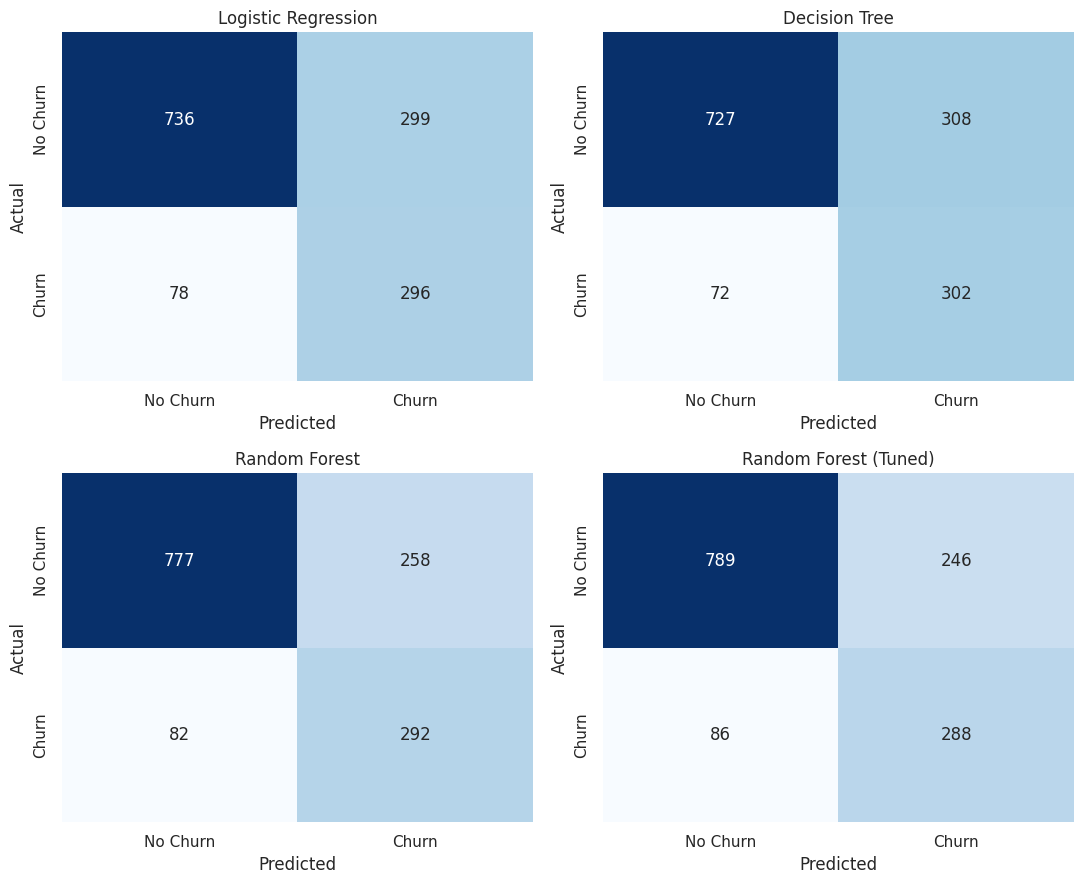

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, name in zip(axes.ravel(), models.keys()):
    cm = confusion_matrix(y_test, y_preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

### Step 6.3 – ROC curves for all models
**What:** The ROC curve plots True Positive Rate (recall) against False Positive Rate for every possible probability threshold. The diagonal dashed line is random guessing.  
**Why:** It compares models independent of any single threshold. The curve closer to the top-left corner is better, and the area under it (AUC) summarises this in one number.  
**Output meaning:** All models are well above the diagonal; the legend shows each AUC value.

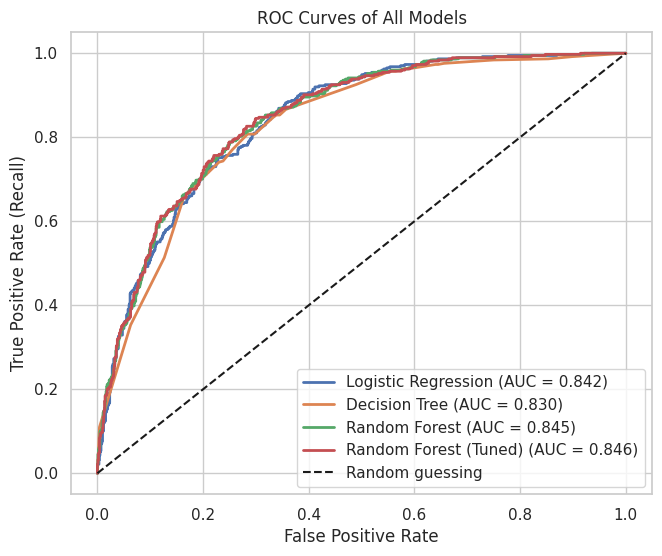

In [30]:
plt.figure(figsize=(7.5, 6))
for name in models.keys():
    fpr, tpr, _ = roc_curve(y_test, y_probs[name])
    auc = roc_auc_score(y_test, y_probs[name])
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves of All Models")
plt.legend(loc="lower right")
plt.show()

### Step 6.4 – Comparison table and bar chart
**What:** All metrics are collected into one DataFrame (sorted by Recall) and shown as a grouped bar chart.  
**Why:** Putting everything side by side makes it easy to compare and choose the best model.  
**Output meaning:** Read across a row to see one model's strengths; read down a column to see which model is best at that metric.

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Decision Tree,0.7303,0.4951,0.8075,0.6138,0.8298
Logistic Regression,0.7324,0.4975,0.7914,0.6109,0.8422
Random Forest,0.7587,0.5309,0.7807,0.6320,0.8454
Random Forest (Tuned),0.7644,0.5393,0.7701,0.6344,0.8461


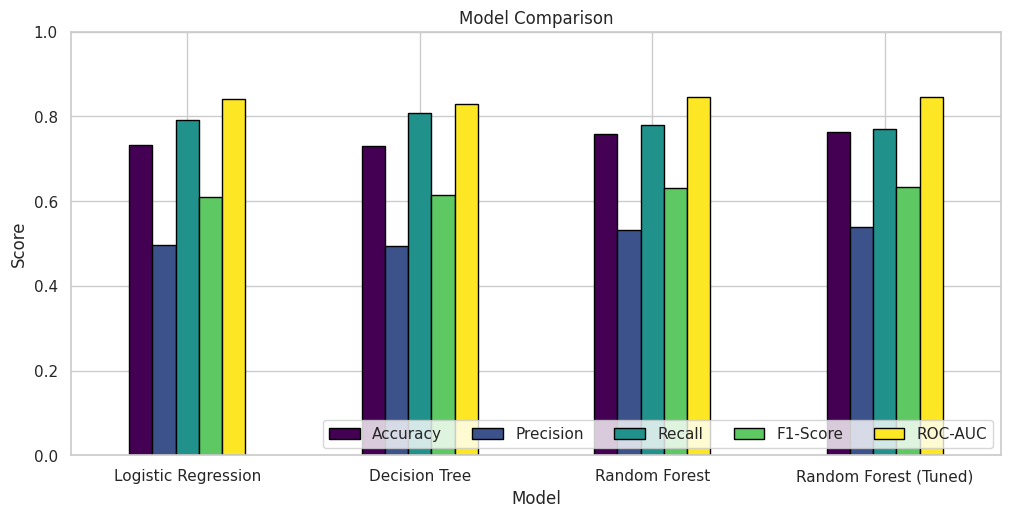

In [31]:
results_df = pd.DataFrame(results).set_index("Model").round(4)
display(results_df.sort_values("Recall", ascending=False))

results_df[["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(12, 5.5), rot=0, colormap="viridis", edgecolor="black")
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="lower right", ncol=5)
plt.show()

### Step 6.5 – Which model is best and why?
**Results on the test set (numbers from this run, `random_state=42`):**

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.732 | 0.498 | 0.791 | 0.611 | 0.842 |
| Decision Tree | 0.730 | 0.495 | 0.808 | 0.614 | 0.830 |
| Random Forest | 0.759 | 0.531 | 0.781 | 0.632 | 0.845 |
| **Random Forest (Tuned)** | **0.764** | **0.539** | 0.770 | **0.634** | **0.846** |

**Why Recall matters most here:** for a telecom company, a **missed churner (false negative)** means losing a customer and all their future revenue, while a **false alarm (false positive)** only costs a small discount or a phone call. So we want a model that catches most churners, even if it raises a few false alarms. That is why we used `class_weight="balanced"` and why accuracy alone is not our main score (a model that always says "No churn" would already be ~73% accurate but would catch no churners).

**Reading the table:**
- The **Decision Tree** has the highest recall (about 81%), but it also has the lowest precision and lowest AUC, and a single shallow tree is less stable.
- **Logistic Regression** is a strong, simple and explainable baseline (recall about 79%, AUC 0.842).
- The **Tuned Random Forest** has the best F1-score, accuracy, precision and ROC-AUC, and still catches about **77% of churners** (recall ≥ 0.75). It is the best *overall* balance, so it is our **final model**.
- The differences between the models are small, which is normal for this dataset. If the company wants even higher recall, the next step (Step 6.5b) shows how lowering the decision threshold can raise recall to about 85%.

The cell below applies this selection rule automatically, so the choice is reproducible rather than hand-picked.

In [32]:
# Selection rule for a telecom company:
#   Step 1 - keep only models that catch at least 75% of churners (Recall >= 0.75)
#   Step 2 - among those, choose the one with the best F1-score (best precision/recall balance)
candidates = results_df[results_df["Recall"] >= 0.75]
best_name = candidates["F1-Score"].idxmax()
print("Selected final model:", best_name)
display(results_df.loc[[best_name]])

Selected final model: Random Forest (Tuned)


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Random Forest (Tuned),0.7644,0.5393,0.7701,0.6344,0.8461


### Step 6.5b – Can we catch even more churners? (changing the decision threshold)
**What:** By default a customer is predicted "Churn" when the churn probability is 0.5 or more. A company that prefers to miss fewer churners can lower this threshold (for example to 0.4 or 0.3). We show what happens to Recall and Precision for the final model.  
**Why:** This is a simple business lever: more recall means fewer missed churners, but also more false alarms (lower precision).  
**Output meaning:** As the threshold goes down, Recall goes up and Precision goes down. The company can pick the balance that fits the cost of a retention offer.

In [33]:
final_name_for_threshold = best_name
_model, _X = models[final_name_for_threshold]
_prob = _model.predict_proba(_X)[:, 1]

rows = []
for t in [0.6, 0.5, 0.4, 0.3]:
    p = (_prob >= t).astype(int)
    rows.append({"Threshold": t,
                 "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p),
                 "F1-Score": f1_score(y_test, p),
                 "Customers flagged": int(p.sum())})
print("Threshold effect for:", final_name_for_threshold)
display(pd.DataFrame(rows).set_index("Threshold").round(3))

Threshold effect for: Random Forest (Tuned)


,Precision,Recall,F1-Score,Customers flagged
Threshold,,,,
0.6,0.588,0.655,0.619,417
0.5,0.539,0.770,0.634,534
0.4,0.488,0.850,0.620,651
0.3,0.441,0.906,0.594,768


### Step 6.6 – Feature importance (Random Forest) and Logistic Regression coefficients
**What:**
- **Random Forest feature importance:** how much each feature helped the trees to split customers correctly (bigger = more important). It does not tell the direction.
- **Logistic Regression coefficients:** because numeric features are scaled, the coefficient shows how strongly a feature pushes the prediction. **Positive** = increases churn risk, **negative** = decreases churn risk.

**Why:** A churn model is only useful to a business if we can explain *why* customers leave.  
**Output meaning:** Top features should match our EDA findings (contract type, tenure, charges, internet service, etc.).

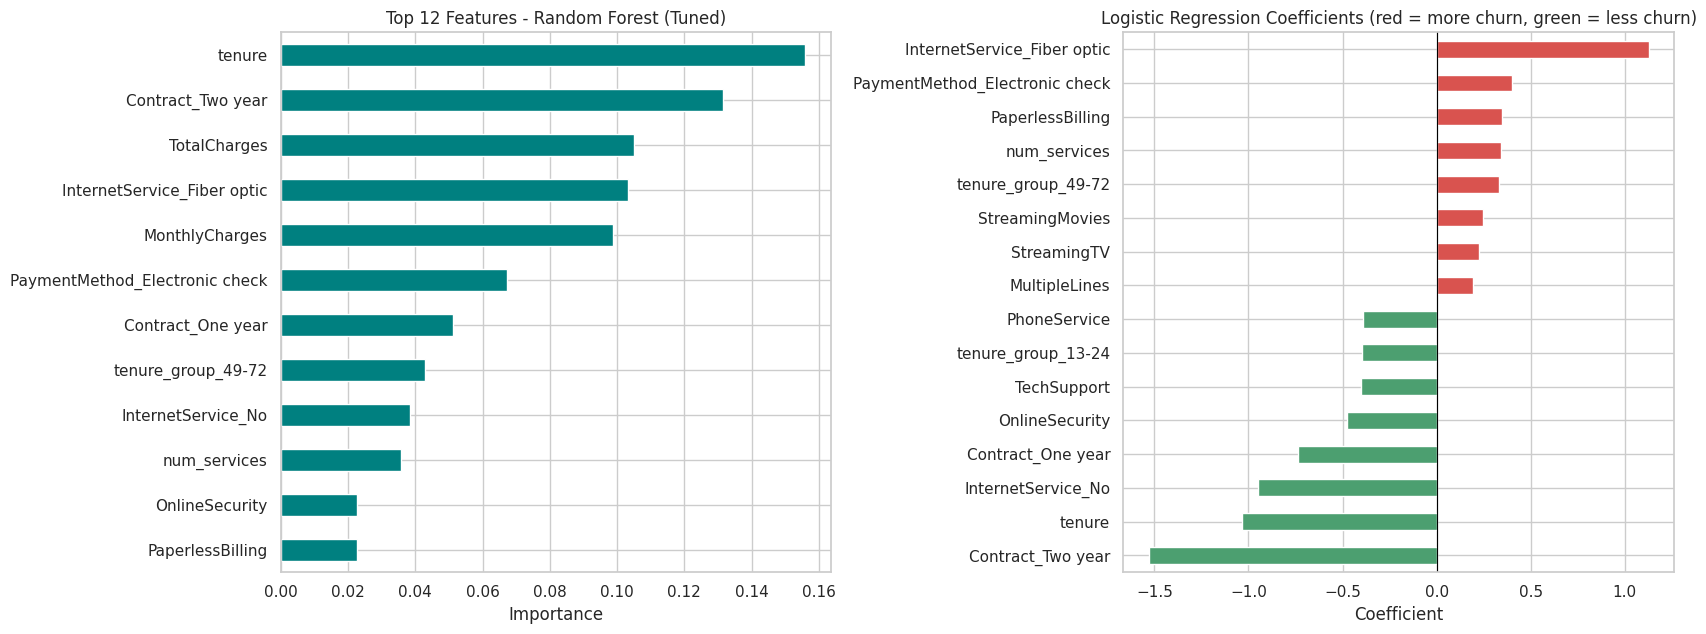

Top 8 Random Forest features:
tenure                            0.156
Contract_Two year                 0.131
TotalCharges                      0.105
InternetService_Fiber optic       0.103
MonthlyCharges                    0.099
PaymentMethod_Electronic check    0.067
Contract_One year                 0.051
tenure_group_49-72                0.043
dtype: float64

Logistic Regression - strongest factors that INCREASE churn:
InternetService_Fiber optic       1.13
PaymentMethod_Electronic check    0.40
PaperlessBilling                  0.35
num_services                      0.34
tenure_group_49-72                0.33
dtype: float64

Logistic Regression - strongest factors that DECREASE churn:
Contract_Two year    -1.53
tenure               -1.03
InternetService_No   -0.95
Contract_One year    -0.74
OnlineSecurity       -0.47
dtype: float64


In [34]:
# --- Random Forest (tuned) feature importance ---
importances = pd.Series(rf_tuned.feature_importances_, index=X_train.columns).sort_values(ascending=False)
top_imp = importances.head(12).iloc[::-1]

# --- Logistic Regression coefficients ---
coefs = pd.Series(log_reg.coef_[0], index=X_train.columns).sort_values()
top_coefs = pd.concat([coefs.head(8), coefs.tail(8)])

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

top_imp.plot(kind="barh", color="teal", ax=axes[0])
axes[0].set_title("Top 12 Features - Random Forest (Tuned)")
axes[0].set_xlabel("Importance")

colors = ["#D9534F" if v > 0 else "#4C9F70" for v in top_coefs.values]
top_coefs.plot(kind="barh", color=colors, ax=axes[1])
axes[1].set_title("Logistic Regression Coefficients (red = more churn, green = less churn)")
axes[1].set_xlabel("Coefficient")
axes[1].axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

print("Top 8 Random Forest features:")
print(importances.head(8).round(3))
print("\nLogistic Regression - strongest factors that INCREASE churn:")
print(coefs.sort_values(ascending=False).head(5).round(2))
print("\nLogistic Regression - strongest factors that DECREASE churn:")
print(coefs.head(5).round(2))

### Step 6.7 – Interpretation of the important features
**What the two charts and printed lists tell us:**
- **Contract type** is one of the strongest signals. A *two-year contract* is the top factor that lowers churn in Logistic Regression and is the 2nd most important feature in the Random Forest. A one-year contract also lowers churn.
- **Tenure** (months with the company) is the most important Random Forest feature and a big negative factor in Logistic Regression: the longer a customer stays, the less likely they are to leave.
- **Fiber optic internet** is the strongest factor that *increases* churn. Customers with fiber pay more and may be unhappy with price or service quality.
- **Electronic check payment** increases churn risk, while **no internet service** and **online security** lower it.
- **MonthlyCharges and TotalCharges** are also important in the Random Forest, which matches the EDA (churners pay more per month and are mostly new).

These findings match the patterns we saw in the EDA, which is a good sign that the models learned real behaviour and not random noise.

**Caution when reading coefficients:** `tenure`, `TotalCharges`, `MonthlyCharges`, `num_services` and `tenure_group` are strongly related to each other (multicollinearity). Because of this, a few Logistic Regression coefficients look odd (for example `num_services` and `tenure_group_49-72` show small positive values). Individual coefficients of related features should be read together, not alone. The Random Forest importance is less affected by this problem.

---
# 7. APPLICATION / PREDICTION

### Step 7.1 – Build one preprocessing function that repeats the training steps
**What:** `preprocess_raw()` takes **raw** customer data (same columns as the original dataset) and applies exactly the same steps we used in training: fix `TotalCharges`, simplify "No internet/phone service", convert SeniorCitizen, create `tenure_group` and `num_services`, map binary columns, one-hot encode, and arrange the columns in the **same order** as the training features.  
**Why:** A model can only understand data prepared in exactly the same way as its training data. Even one missing or re-ordered column would give wrong predictions.  
**The final check:** we run the function on the raw rows of the test set and verify (`assert`) that the result is **identical** to `X_test`. If the assertion passes, the pipeline is proven consistent.  
**Output meaning:** `True` / success message means the prediction pipeline matches the training pipeline.

In [35]:
feature_columns = list(X_train.columns)     # exact order the model was trained on

def preprocess_raw(raw_df):
    """Turn raw customer rows (original dataset format) into model-ready features."""
    d = raw_df.copy()

    # 1) remove ID if present
    d = d.drop(columns=["customerID"], errors="ignore")

    # 2) TotalCharges -> number (blank -> 0). If it is not supplied, estimate it.
    if "TotalCharges" not in d.columns:
        d["TotalCharges"] = d["tenure"] * d["MonthlyCharges"]
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce").fillna(0)

    # 3) SeniorCitizen can be given as 0/1 or Yes/No
    d["SeniorCitizen"] = d["SeniorCitizen"].map({0: "No", 1: "Yes", "No": "No", "Yes": "Yes"})

    # 4) simplify "No internet service" / "No phone service" -> "No"
    for col in service_cols:
        d[col] = d[col].replace("No internet service", "No")
    d["MultipleLines"] = d["MultipleLines"].replace("No phone service", "No")

    # 5) feature engineering (same as training)
    d["tenure_group"] = pd.cut(d["tenure"], bins=[-1, 12, 24, 48, 72],
                               labels=["0-12", "13-24", "25-48", "49-72"]).astype(str)
    d["num_services"] = ((d["PhoneService"] == "Yes").astype(int)
                         + (d["MultipleLines"] == "Yes").astype(int)
                         + (d["InternetService"] != "No").astype(int)
                         + sum((d[c] == "Yes").astype(int) for c in service_cols))

    # 6) binary encoding
    for col in yes_no_cols:
        d[col] = d[col].map({"No": 0, "Yes": 1})
    d["gender"] = d["gender"].map({"Female": 0, "Male": 1})

    # 7) one-hot encoding, then force the SAME columns/order as training.
    #    (reindex adds missing dummy columns as 0 and drops the 'first' category columns)
    d = pd.get_dummies(d, columns=multi_cat_cols, dtype=int)
    d = d.reindex(columns=feature_columns, fill_value=0)
    return d

# ---- Consistency test: raw test rows -> function -> must equal X_test ----
check = preprocess_raw(df_raw.loc[X_test.index].drop(columns=["Churn"]))
assert check.shape == X_test.shape, "Shape mismatch!"
assert (check.values == X_test.values).all(), "Values mismatch!"
print("SUCCESS: preprocess_raw() reproduces the training pipeline exactly.")
print("Shape checked:", check.shape)

SUCCESS: preprocess_raw() reproduces the training pipeline exactly.
Shape checked: (1409, 27)


### Step 7.2 – Choose the final model and write `predict_churn()`
**What:** `predict_churn(customer_dict)` does 4 things: (1) converts the dictionary to a one-row table, (2) preprocesses it, (3) scales numeric columns **if the final model needs scaling** (only Logistic Regression does), and (4) returns `"Churn"` or `"No Churn"` plus the churn probability.  
**Why:** This is the "application" part – it shows how a real customer record becomes a prediction.  
**Rule:** if the churn probability is 0.5 or more, we predict "Churn".  
**Output meaning:** The cell prints which model is used as the final model.

In [36]:
final_models = {
    "Logistic Regression": (log_reg, True),       # (model, needs_scaling)
    "Decision Tree": (dec_tree, False),
    "Random Forest": (rand_forest, False),
    "Random Forest (Tuned)": (rf_tuned, False),
}
final_model, needs_scaling = final_models[best_name]
print("Final model used for prediction:", best_name, "| needs scaling:", needs_scaling)

def predict_churn(customer_dict, threshold=0.5):
    """Input : dictionary with raw customer information (original dataset columns).
       Output: ("Churn" or "No Churn", churn probability)"""
    new_raw = pd.DataFrame([customer_dict])
    X_new = preprocess_raw(new_raw)

    if needs_scaling:                                   # same scaler fitted on the training data
        X_new[numeric_cols] = scaler.transform(X_new[numeric_cols])

    prob = final_model.predict_proba(X_new)[0, 1]
    label = "Churn" if prob >= threshold else "No Churn"
    return label, prob

Final model used for prediction: Random Forest (Tuned) | needs scaling: False


### Step 7.3 – Demonstration on 3 sample customers
**What:** We create three customers:
1. **High-risk:** month-to-month contract, fiber optic, electronic check, only 2 months tenure, no add-ons.
2. **Low-risk:** two-year contract, 60 months tenure, automatic payment, many add-ons.
3. **Borderline:** a mixed profile – a protective one-year contract, but risky signs too (fiber optic, electronic check, only 14 months tenure, no tech support). The model's probability should be close to 50%.

**Why:** To show clearly how input information becomes a Churn / No Churn decision.  
**Output meaning:** For each customer the inputs and the predicted label with churn probability are printed. A high probability means high risk.

In [37]:
high_risk = {
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 2,
    "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
    "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
    "StreamingTV": "No", "StreamingMovies": "No", "Contract": "Month-to-month",
    "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
    "MonthlyCharges": 80.35, "TotalCharges": 160.7,
}

low_risk = {
    "gender": "Male", "SeniorCitizen": 0, "Partner": "Yes", "Dependents": "Yes", "tenure": 60,
    "PhoneService": "Yes", "MultipleLines": "Yes", "InternetService": "DSL",
    "OnlineSecurity": "Yes", "OnlineBackup": "Yes", "DeviceProtection": "Yes", "TechSupport": "Yes",
    "StreamingTV": "No", "StreamingMovies": "No", "Contract": "Two year",
    "PaperlessBilling": "No", "PaymentMethod": "Bank transfer (automatic)",
    "MonthlyCharges": 64.40, "TotalCharges": 3864.0,
}

borderline = {
    "gender": "Male", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 14,
    "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
    "OnlineSecurity": "No", "OnlineBackup": "Yes", "DeviceProtection": "No", "TechSupport": "No",
    "StreamingTV": "No", "StreamingMovies": "No", "Contract": "One year",
    "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
    "MonthlyCharges": 80.0, "TotalCharges": 1120.0,
}

samples = {"1) HIGH-RISK customer": high_risk,
           "2) LOW-RISK customer": low_risk,
           "3) BORDERLINE customer": borderline}

for title, cust in samples.items():
    label, prob = predict_churn(cust)
    print("=" * 70)
    print(title)
    print("=" * 70)
    for k, v in cust.items():
        print(f"  {k:18s}: {v}")
    print(f"\n  >>> PREDICTION: {label}   (churn probability = {prob*100:.1f}%)\n")

1) HIGH-RISK customer
  gender            : Female
  SeniorCitizen     : 0
  Partner           : No
  Dependents        : No
  tenure            : 2
  PhoneService      : Yes
  MultipleLines     : No
  InternetService   : Fiber optic
  OnlineSecurity    : No
  OnlineBackup      : No
  DeviceProtection  : No
  TechSupport       : No
  StreamingTV       : No
  StreamingMovies   : No
  Contract          : Month-to-month
  PaperlessBilling  : Yes
  PaymentMethod     : Electronic check
  MonthlyCharges    : 80.35
  TotalCharges      : 160.7

  >>> PREDICTION: Churn   (churn probability = 85.1%)

2) LOW-RISK customer
  gender            : Male
  SeniorCitizen     : 0
  Partner           : Yes
  Dependents        : Yes
  tenure            : 60
  PhoneService      : Yes
  MultipleLines     : Yes
  InternetService   : DSL
  OnlineSecurity    : Yes
  OnlineBackup      : Yes
  DeviceProtection  : Yes
  TechSupport       : Yes
  StreamingTV       : No
  StreamingMovies   : No
  Contract          :

### Step 7.4 – Save the final model and preprocessing objects with joblib
**What:** We save the final model, the fitted scaler, the list of feature columns, and the numeric column names into `.joblib` files.  
**Why:** So the system can be reused later (for example in a web app) without retraining. The scaler and feature list must be saved with the model, because the same preprocessing is needed at prediction time.  
**Output meaning:** The files appear in the notebook folder. We also reload the model and test it once to prove the saved files work.

In [38]:
joblib.dump(final_model,     "churn_final_model.joblib")
joblib.dump(scaler,          "churn_scaler.joblib")
joblib.dump(feature_columns, "churn_feature_columns.joblib")
joblib.dump({"numeric_cols": numeric_cols, "needs_scaling": needs_scaling, "model_name": best_name},
            "churn_model_info.joblib")

for f in ["churn_final_model.joblib", "churn_scaler.joblib", "churn_feature_columns.joblib", "churn_model_info.joblib"]:
    print(f"Saved: {f}  ({os.path.getsize(f)/1024:.1f} KB)")

# Reload and test: probability must be identical to the in-memory model
loaded_model = joblib.load("churn_final_model.joblib")
loaded_scaler = joblib.load("churn_scaler.joblib")
x = preprocess_raw(pd.DataFrame([high_risk]))
if needs_scaling:
    x[numeric_cols] = loaded_scaler.transform(x[numeric_cols])
print("\nReloaded model probability for the high-risk customer:", round(loaded_model.predict_proba(x)[0, 1], 4))

Saved: churn_final_model.joblib  (4983.3 KB)
Saved: churn_scaler.joblib  (1.0 KB)
Saved: churn_feature_columns.joblib  (0.5 KB)
Saved: churn_model_info.joblib  (0.1 KB)



Reloaded model probability for the high-risk customer: 0.8513


---
# 8. CONCLUSION

### 8.1 Best-performing model and why
The **Tuned Random Forest** gave the best overall performance on unseen test data: Accuracy ≈ 76%, Precision ≈ 54%, **Recall ≈ 77%**, F1 ≈ 0.63 and ROC-AUC ≈ 0.85. It combines many decision trees, so it captures non-linear patterns and interactions (for example, contract type together with tenure) while being more stable than one tree. Logistic Regression was close and is easier to explain, and the Decision Tree had the highest recall but weaker precision and AUC. Because missing a churner is more costly than a false alarm, we selected the model that keeps recall high (≥ 75%) while giving the best F1-score. Lowering the decision threshold can raise recall further (about 85% at a threshold of 0.4) at the cost of more false alarms.

### 8.2 Key observations from the data
- About **26.5%** of customers churned (imbalanced data: roughly 73% stay vs 27% leave).
- **Month-to-month contracts** churn at about 43%, versus about 11% (one-year) and 3% (two-year).
- **New customers** (first 12 months) churn the most (about 47%); churn falls steadily with tenure.
- **Fiber optic** customers (about 42%) and **electronic check** payers (about 45%) churn the most.
- Customers **without tech support / online security** and **senior citizens** also churn more.
- The most important model features were tenure, contract type, internet service type, and monthly/total charges.

### 8.3 Limitations of this work
- **Class imbalance:** only about 1 in 4 customers churned. We handled it with class weights, but precision stays modest (about 54%), so roughly half of the customers flagged as "churn" would actually have stayed.
- **One company, one time period:** the data comes from a single telecom company (a snapshot). The model may not work well for another company, country (for example Pakistan) or after market changes.
- **No time-series behaviour:** the dataset is one row per customer. It does not show how usage, complaints, call-centre contacts or bills changed over time, which are strong churn signals in real life.
- **Possible bias:** features such as gender, senior-citizen status and partner/dependents could lead to unfair treatment of some groups if used carelessly. Business decisions should be based on behaviour and service quality, not on personal characteristics.
- **Correlated features and the test set size:** several numeric features overlap, and results come from one train/test split (1,409 test customers), so scores can change a little with a different split. The model predicts *who* may leave, not *why* with certainty (it shows association, not cause).

### 8.4 How a telecom company can use this system
- **Targeted retention offers:** run the model on all customers each month, rank them by churn probability, and call or message the highest-risk customers first with discounts, free upgrades or better plans.
- **Encourage long-term contracts:** since month-to-month customers churn the most, offer discounts or free add-ons to move them to one-year or two-year contracts.
- **Improve services:** promote tech support and online security bundles, review fiber optic pricing/quality, and encourage automatic payment instead of electronic checks.
- **Welcome programme for new customers:** because the first year is the riskiest, give new customers extra support and check-in calls.
- **Smart budgeting:** use the probability and the decision threshold to balance the cost of retention offers against the revenue saved by keeping a customer.

**Final remark:** This notebook completed the full machine learning pipeline – loading, cleaning, EDA, feature engineering, training, evaluation, and a working `predict_churn()` application with saved model files.